In [1]:
# Run only if packages are missing:
# %pip install torch torchvision scipy numpy matplotlib scikit-learn

from pathlib import Path
import random
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Limit CPU threads to avoid unnecessary overhead on small batches.
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

QUICK_RUN = False
batch_size = 32
dimz = 20
var_x = 0.1
lr = 1e-3
epochs = 3 if QUICK_RUN else 20

# Works when launched from this folder or its parent ML_Health folder.
project_dir = Path.cwd()
if (project_dir / "multi-view-vae").is_dir():
    project_dir = project_dir / "multi-view-vae"
data_dir = project_dir / "data"
output_dir = project_dir / "practice_outputs" / ("quick" if QUICK_RUN else "full")
output_dir.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Mode:", "small practice run" if QUICK_RUN else "full experiment")
print("Outputs:", output_dir)


Device: mps
Mode: full experiment
Outputs: /Users/collin/Documents/ML_Health/multi-view-vae/practice_outputs/full


In [2]:
mnist_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
svhn_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

mnist_train = datasets.MNIST(data_dir, train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(data_dir, train=False, download=True, transform=mnist_transform)
svhn_train = datasets.SVHN(data_dir, split="train", download=True, transform=svhn_transform)
svhn_test = datasets.SVHN(data_dir, split="test", download=True, transform=svhn_transform)

print("MNIST:", len(mnist_train), "train /", len(mnist_test), "test")
print("SVHN:", len(svhn_train), "train /", len(svhn_test), "test")


MNIST: 60000 train / 10000 test
SVHN: 73257 train / 26032 test


## 3. Build pairs without leaking validation images
We first split **each original training dataset** into 90% training and 10% validation. `stratify` preserves approximately the same digit proportions. Only then do we form pairs. This prevents an SVHN image reused in several pairs from appearing in both training and validation.

One sample is `(MNIST image, SVHN image, shared label)`. For each MNIST image, we randomly choose an SVHN image with the same digit. Choices are fixed by a seed. Sampling is with replacement: SVHN images may be reused or unused. The label is used to build pairs and color plots; it is **not an input to the VAE or its loss**.

These are semantic pairs, not photographs of the same physical digit. Style, background and handwriting are not aligned.


In [3]:
mnist_train_ids, mnist_val_ids = train_test_split(
    np.arange(len(mnist_train)), test_size=0.1,
    stratify=mnist_train.targets.numpy(), random_state=SEED,
)
svhn_train_ids, svhn_val_ids = train_test_split(
    np.arange(len(svhn_train)), test_size=0.1,
    stratify=svhn_train.labels, random_state=SEED,
)

class PairedDigits(Dataset):
    def __init__(self, mnist, svhn, mnist_ids=None, svhn_ids=None, seed=42):
        self.mnist = mnist
        self.svhn = svhn
        if mnist_ids is None:
            mnist_ids = np.arange(len(mnist))
        if svhn_ids is None:
            svhn_ids = np.arange(len(svhn))
        svhn_ids = np.asarray(svhn_ids)
        rng = np.random.default_rng(seed)

        # A lookup table: digit -> eligible SVHN image indices.
        candidates = {}
        for digit in range(10):
            candidates[digit] = svhn_ids[svhn.labels[svhn_ids] == digit]
            assert len(candidates[digit]) > 0

        self.pairs = []
        for i in mnist_ids:
            label = int(mnist.targets[int(i)])
            j = int(rng.choice(candidates[label]))
            self.pairs.append((int(i), j))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        i, j = self.pairs[index]
        x_mnist, label_mnist = self.mnist[i]
        x_svhn, label_svhn = self.svhn[j]
        assert int(label_mnist) == int(label_svhn)
        return x_mnist, x_svhn, int(label_mnist)

paired_train = PairedDigits(mnist_train, svhn_train, mnist_train_ids, svhn_train_ids, SEED)
paired_val = PairedDigits(mnist_train, svhn_train, mnist_val_ids, svhn_val_ids, SEED + 1)
paired_test = PairedDigits(mnist_test, svhn_test, seed=SEED + 2)

# Verify every pair using labels, without loading every image.
for dataset in [paired_train, paired_val, paired_test]:
    assert all(int(dataset.mnist.targets[i]) == int(dataset.svhn.labels[j])
               for i, j in dataset.pairs)
assert set(mnist_train_ids).isdisjoint(mnist_val_ids)
assert set(svhn_train_ids).isdisjoint(svhn_val_ids)
print("All pairs have matching labels; training and validation sources are disjoint.")

# Random subsets keep the practice run short, including a shuffled test subset.
def small_subset(dataset, size, seed):
    rng = np.random.default_rng(seed)
    ids = rng.permutation(len(dataset))[:min(size, len(dataset))].tolist()
    return Subset(dataset, ids)

train_data = small_subset(paired_train, 2048, SEED) if QUICK_RUN else paired_train
val_data = small_subset(paired_val, 256, SEED) if QUICK_RUN else paired_val
test_data = small_subset(paired_test, 512, SEED) if QUICK_RUN else paired_test

trainloader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED), num_workers=0)
valloader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
testloader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)
print("Pairs used: train", len(train_data), "validation", len(val_data), "test", len(test_data))


All pairs have matching labels; training and validation sources are disjoint.
Pairs used: train 54000 validation 6000 test 10000


## 4. Inspect the paired data
Each column must show the same digit across the two rows. Undo normalization only for display. The helper below also saves figures for the report.


MNIST (32, 3, 64, 64) SVHN (32, 3, 64, 64)


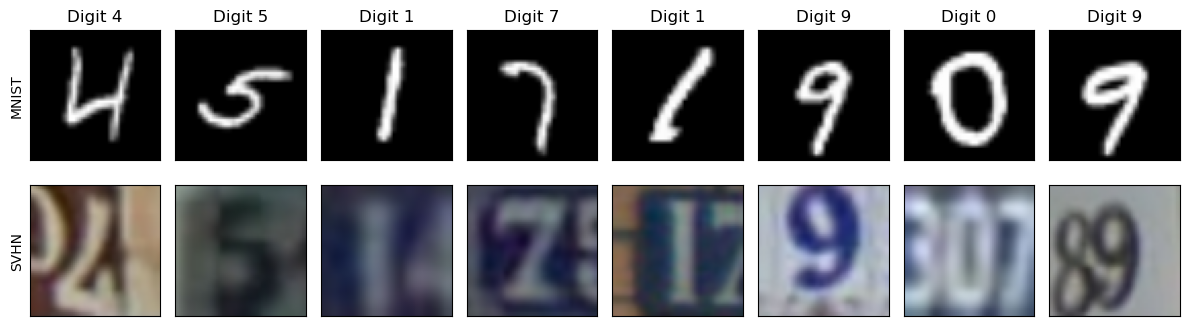

In [4]:
def show_rows(rows, row_names, labels=None, filename=None, n=8):
    n = min(n, min(len(row) for row in rows))
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.8 * len(rows)), squeeze=False)
    for r, (images, name) in enumerate(zip(rows, row_names)):
        for c in range(n):
            img = (images[c].detach().cpu() / 2 + 0.5).clamp(0, 1)
            axes[r, c].imshow(img.permute(1, 2, 0).numpy())
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0 and labels is not None:
                axes[r, c].set_title("Digit " + str(int(labels[c])))
        axes[r, 0].set_ylabel(name)
    fig.tight_layout()
    if filename is not None:
        fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()

mnist_batch, svhn_batch, labels = next(iter(trainloader))
print("MNIST", tuple(mnist_batch.shape), "SVHN", tuple(svhn_batch.shape))
show_rows([mnist_batch, svhn_batch], ["MNIST", "SVHN"], labels, "paired_data.png")


## 5. Encoder: the same convolutional network as your lab
The spatial sizes are **64 → 32 → 16 → 8 → 4 → 1**. The final 256 features become `2 * dimz` numbers: one mean and one positive variance per latent coordinate.

We retain the lab's `Softplus(0.5 * raw_output)` convention. These outputs are **variances, not log variances**. Adding a small epsilon keeps division and logarithms safe. A latent sample is

$$z = \mu + \sqrt{v}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

The reparameterization trick lets gradients reach the encoder through this sample. We will instantiate this class twice, with independent weights.


In [5]:
class encoder(nn.Module):
    
    def __init__(self,dimz,channels=3,var_x=0.1):

        super().__init__()
        
        self.dimz = dimz    #dimz is k, the dimension of the latent space

        # self.conv1 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, 
                               kernel_size=4, stride=2, padding=1)
        
        self.relu = nn.ReLU()
        
        # self.conv2 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, 
                               kernel_size=4, stride=2, padding=1)

        # self.conv3 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, 
                               kernel_size=4, stride=2, padding=1)      

        # self.conv4 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1        
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64, 
                               kernel_size=4, stride=2, padding=1) 

        # self.conv5 is a convolutional layer, with 256 output channels, kernel size 4, stride 1,
        # and padding 0                                
        
        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256, 
                               kernel_size=4, stride=1, padding=0) 

        # self.linear is a linear layer with dimz*2 outputs
        self.linear = nn.Linear(256,dimz*2)
        
        self.softplus = nn.Softplus()
        
    def forward(self,x):

        # The forward method to project and image into a 2dimz dimensional vector
        
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z))
        z = self.relu(self.conv5(z))
        # Transform z into a 256-dim vector
        z = z.view(-1,256)
        z = self.linear(z)
        
        return z
    
    def encode_and_sample(self,x,flag_sample=True):

        # This methods compute both the posterior mean and variance
        # Also we obtain a sample from the posterior using the
        # reparameterization trick.

        # We obtain the encoder projection using the forward method
        
        z = self.forward(x)

        # The mean is the first dimz components of the forward output
        
        mu = z[:, :self.dimz]

        # We compute the variance from the last dimz components using a 
        # soft plus
        var = self.softplus(0.5 * z[:, self.dimz:]) + 1e-6
        
        sample = None
        
        if(flag_sample==True):
            
            eps = torch.randn_like(var) 
            
            sample = mu + eps*(var**0.5)
        
        return mu,var,sample


## 6. Decoder: reverse the encoder
This is the decoder from your notebook. It expands `z` into 256 features and uses transposed convolutions to produce a 3 × 64 × 64 image. `Tanh` bounds the predicted pixel means to [-1, 1].

There will be one MNIST decoder and one SVHN decoder. They receive the **same latent vector** but learn different image appearances. The fixed `var_x` used later describes observation noise, not latent uncertainty.


In [6]:
class decoder(nn.Module):
    
    def __init__(self,dimz,channels=3,var_x=0.1):
        
        super().__init__()

        # We expand z into a 256 dimensional vector 
        
        self.linear = nn.Linear(dimz,256)
        
        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

        # self.tconv1 is a convolutional layer, with 64 output channels, kernel size 4, stride 1,
        # and padding 0 
        
        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1,padding=0)

        # self.tconv2 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1         
        
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2,padding=1)

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2,padding=1)

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2,padding=1)

        # self.tconv3 is a convolutional layer, with channels output channels, kernel size 4, stride 2,
        # and padding 1        
        
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2,padding=1)
        
    def forward(self,z):

        x = self.relu(self.linear(z).view(-1,256,1,1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))   
        return x
    
    def decode(self,z):

        # This function simply calls the forward method
        
        return self.forward(z)


## 7. Product of experts: combine the two views
Each encoder supplies a diagonal Gaussian expert. We multiply the available experts with a standard normal prior, counting that prior **once**:

$$q(z\mid x_M,x_S)\propto p(z)\,\widetilde q_M(z\mid x_M)\,\widetilde q_S(z\mid x_S).$$

For each latent coordinate, precision is inverse variance. With prior mean 0 and precision 1:

$$v = \left(1+\sum_i 1/v_i\right)^{-1},\qquad
\mu = v\sum_i \mu_i/v_i.$$

A more certain expert (smaller variance) contributes more to the combined mean. The encoder outputs are expert factors; the actual inferred posterior includes the prior. With only one image, combine that expert with the prior. With neither image, generation uses the prior directly.

**Check by hand:** two experts with mean 2 and variance 1, plus the prior, give variance 1/3 and mean 4/3.


In [7]:
def product_of_experts(mus, variances):
    # mus and variances are lists of tensors shaped [batch_size, dimz].
    precision = torch.ones_like(variances[0])  # prior precision = 1
    weighted_mu = torch.zeros_like(mus[0])    # prior mean = 0
    for mu, var in zip(mus, variances):
        precision = precision + 1.0 / var
        weighted_mu = weighted_mu + mu / var
    var = 1.0 / precision
    mu = var * weighted_mu
    return mu, var

example_mu, example_var = product_of_experts(
    [torch.tensor([[2.0]]), torch.tensor([[2.0]])],
    [torch.tensor([[1.0]]), torch.tensor([[1.0]])],
)
assert torch.allclose(example_mu, torch.tensor([[4.0 / 3.0]]))
assert torch.allclose(example_var, torch.tensor([[1.0 / 3.0]]))
print("Product-of-experts hand calculation passed.")


Product-of-experts hand calculation passed.


## 8. Gaussian reconstruction likelihood
This is your existing `eval_Gaussian_LL`. It sums over pixels and then over the batch. Both image types use the same size and fixed observation variance, so we give them equal reconstruction weights.

A Gaussian likelihood is compatible with our [-1, 1] images. Do not use binary cross-entropy directly on negative target pixels. Because this is a continuous density, its negative log-likelihood is not required to be positive.


In [8]:
def eval_Gaussian_LL(x,mu_x,var_x):

    # x is a mini-batch of images. It has dimension [Batch,3,dimx,dimx]

    # mu_x is a mini-batch of reconstructed images. It has dimension [Batch,3,dimx,dimx]

    # var_x is a torch constant

    D = x.shape[1] * x.shape[2] * x.shape[3]   # Dimension of the image

    x = x.reshape(-1, D)

    mu_x = mu_x.reshape(-1, D)

    var_x = torch.ones_like(mu_x) * var_x

    # Constant term in the gaussian distribution
    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)

    # log-likelihood per datapoint

    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))
    
    # Accumulated Gaussian log-likelihood for all datapoints in the batch
    logp = torch.sum(logp_data)

    return logp,logp_data


## 9. Joint VAE and loss
Compare this class with `VAE` in your notebook. The changes are two encoders, two decoders, and an `infer` method that fuses the available experts. `None` means that input is missing.

For any available input subset $A$, we reconstruct **both** targets in a known training pair:

$$\mathcal L_A = -\log p(x_M\mid z_A)-\log p(x_S\mid z_A)
+\mathrm{KL}\big(q_A(z)\,\|\,\mathcal N(0,I)\big).$$

We average three losses: **both images available, only MNIST available, and only SVHN available**. Thus the MNIST-only path explicitly learns to generate SVHN, and vice versa. This is a paired-data objective using three inference distributions; it is not an exact reproduction of the paper's subsampled objective. Each term bounds the same paired log-likelihood, but uses different inputs for inference.

The KL expression is the same as your lab. Each loss is divided by the batch size so that a short final batch does not change the gradient scale. There is one KL term per inference path, not one per decoder.


In [9]:
class JointVAE(nn.Module):
    def __init__(self, dimz, channels=3, var_x=0.1):
        super().__init__()
        self.dimz = dimz
        self.var_x = var_x
        self.encoder_mnist = encoder(dimz, channels, var_x)
        self.encoder_svhn = encoder(dimz, channels, var_x)
        self.decoder_mnist = decoder(dimz, channels, var_x)
        self.decoder_svhn = decoder(dimz, channels, var_x)

    def infer(self, x_mnist=None, x_svhn=None):
        mus, variances = [], []
        if x_mnist is not None:
            mu, var, _ = self.encoder_mnist.encode_and_sample(x_mnist, flag_sample=False)
            mus.append(mu)
            variances.append(var)
        if x_svhn is not None:
            mu, var, _ = self.encoder_svhn.encode_and_sample(x_svhn, flag_sample=False)
            mus.append(mu)
            variances.append(var)
        if not mus:
            raise ValueError("Provide at least one image; use sample() for prior generation.")
        return product_of_experts(mus, variances)

    def forward(self, x_mnist=None, x_svhn=None, flag_sample=True):
        mu_z, var_z = self.infer(x_mnist, x_svhn)
        if flag_sample:
            z = mu_z + torch.randn_like(var_z) * torch.sqrt(var_z)
        else:
            z = mu_z
        mu_mnist = self.decoder_mnist.decode(z)
        mu_svhn = self.decoder_svhn.decode(z)
        return mu_mnist, mu_svhn, mu_z, var_z

    def loss_function(self, x_mnist, x_svhn, mu_mnist, mu_svhn, mu_z, var_z):
        logp_mnist, _ = eval_Gaussian_LL(x_mnist, mu_mnist, self.var_x)
        logp_svhn, _ = eval_Gaussian_LL(x_svhn, mu_svhn, self.var_x)
        reconstruction = -logp_mnist - logp_svhn
        KLz = -0.5 * torch.sum(1 + torch.log(var_z) - mu_z.pow(2) - var_z)
        n = x_mnist.shape[0]
        return (reconstruction + KLz) / n, reconstruction / n, KLz / n

    def paired_loss(self, x_mnist, x_svhn):
        # Targets stay the same; only the information given to the encoder changes.
        losses, recs, kls = [], [], []
        for input_mnist, input_svhn in [(x_mnist, x_svhn), (x_mnist, None), (None, x_svhn)]:
            outputs = self.forward(input_mnist, input_svhn)
            loss, rec, kl = self.loss_function(x_mnist, x_svhn, *outputs)
            losses.append(loss)
            recs.append(rec)
            kls.append(kl)
        return torch.stack(losses).mean(), torch.stack(recs).mean(), torch.stack(kls).mean()

    def sample(self, num_imgs):
        device = next(self.parameters()).device
        z = torch.randn(num_imgs, self.dimz, device=device)
        return self.decoder_mnist.decode(z), self.decoder_svhn.decode(z)


## 10. Check the model before training
Check all three inference routes, image sizes, finite loss, and gradients to all four networks. These checks catch wiring errors before a long training run. The output is still random because no learning has happened yet.


In [10]:
torch.manual_seed(SEED)
my_vae = JointVAE(dimz=dimz, var_x=var_x).to(device)
x_mnist = mnist_batch[:2].to(device)
x_svhn = svhn_batch[:2].to(device)
for a, b in [(x_mnist, x_svhn), (x_mnist, None), (None, x_svhn)]:
    with torch.no_grad():
        out_m, out_s, mu, var = my_vae(a, b)
    assert out_m.shape == out_s.shape == x_mnist.shape
    assert mu.shape == var.shape == (2, dimz)
    assert (var > 0).all()
loss, rec, kl = my_vae.paired_loss(x_mnist, x_svhn)
assert torch.isfinite(loss)
loss.backward()
for network in [my_vae.encoder_mnist, my_vae.encoder_svhn,
                my_vae.decoder_mnist, my_vae.decoder_svhn]:
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in network.parameters())
my_vae.zero_grad(set_to_none=True)
print("Shapes, missing-view routes, loss and gradients passed.")
print("Initial loss / reconstruction / KL:", loss.item(), rec.item(), kl.item())


Shapes, missing-view routes, loss and gradients passed.
Initial loss / reconstruction / KL: 54761.85546875 54757.76171875 4.091373920440674


## 11. Train, validate, and save the best model
This follows the lab's `VAE_extended` style, but uses a standalone training function to keep the model class readable. Each batch performs: clear gradients → forward/loss → backward → optimizer step.

Validation uses no gradients and no parameter updates. It uses sampled latent vectors, like training, so its loss is a Monte Carlo estimate and may fluctuate. We choose the checkpoint with the lowest validation loss, never using the test set to select an epoch. Curves show losses **per pair**, averaged over the three inference routes.

The Gaussian reconstruction term sums 24,576 pixel-channel values for each pair. Its magnitude can greatly exceed KL; this is expected from these units. The quick run is mainly a functionality check. For final conclusions, run full mode, examine convergence, and report the actual settings.


In [11]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(3)
    n_pairs = 0
    for x_mnist, x_svhn, _ in loader:
        x_mnist = x_mnist.to(device)
        x_svhn = x_svhn.to(device)
        with torch.set_grad_enabled(training):
            if training:
                optimizer.zero_grad()
            loss, rec, kl = model.paired_loss(x_mnist, x_svhn)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; check variances and learning rate.")
            if training:
                loss.backward()
                optimizer.step()
        n = x_mnist.shape[0]
        totals += np.array([loss.item(), rec.item(), kl.item()]) * n
        n_pairs += n
    return totals / n_pairs

optimizer = optim.Adam(my_vae.parameters(), lr=lr)
history = {"train": [], "val": []}
best_val = float("inf")
best_epoch = 0
checkpoint_path = output_dir / "joint_vae_best.pth"
start = time.time()

for epoch in range(epochs):
    train_metrics = run_epoch(my_vae, trainloader, optimizer)
    val_metrics = run_epoch(my_vae, valloader)
    history["train"].append(train_metrics.tolist())
    history["val"].append(val_metrics.tolist())
    if val_metrics[0] < best_val:
        best_val = float(val_metrics[0])
        best_epoch = epoch + 1
        torch.save(my_vae.state_dict(), checkpoint_path)
    print(f"Epoch {epoch + 1:02d}/{epochs} | train {train_metrics[0]:.2f} | "
          f"val {val_metrics[0]:.2f} | KL {train_metrics[2]:.2f} | "
          f"elapsed {(time.time() - start) / 60:.1f} min", flush=True)

my_vae.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
my_vae.eval()
run_info = {
    "quick_run": QUICK_RUN, "seed": SEED, "dimz": dimz, "var_x": var_x,
    "lr": lr, "batch_size": batch_size, "epochs": epochs, "best_epoch": best_epoch,
    "train_pairs": len(train_data), "val_pairs": len(val_data), "test_pairs": len(test_data),
    "device": str(device), "torch_version": str(torch.__version__),
    "training_seconds": time.time() - start, "history": history,
}
(output_dir / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("Restored best validation checkpoint, epoch", best_epoch)


Epoch 01/20 | train 7789.13 | val 5111.57 | KL 85.98 | elapsed 1.4 min
Epoch 02/20 | train 4601.42 | val 4098.05 | KL 75.85 | elapsed 2.8 min
Epoch 03/20 | train 3851.49 | val 3762.05 | KL 78.43 | elapsed 4.3 min
Epoch 04/20 | train 3532.51 | val 3571.37 | KL 77.21 | elapsed 5.9 min
Epoch 05/20 | train 3361.17 | val 3445.50 | KL 76.68 | elapsed 7.3 min
Epoch 06/20 | train 3243.95 | val 3377.34 | KL 76.67 | elapsed 8.8 min
Epoch 07/20 | train 3151.55 | val 3295.63 | KL 76.89 | elapsed 10.3 min
Epoch 08/20 | train 3090.29 | val 3288.58 | KL 77.14 | elapsed 11.8 min
Epoch 09/20 | train 3032.73 | val 3285.74 | KL 76.90 | elapsed 13.4 min
Epoch 10/20 | train 2994.47 | val 3269.54 | KL 77.35 | elapsed 14.9 min
Epoch 11/20 | train 2949.03 | val 3213.38 | KL 77.47 | elapsed 16.6 min
Epoch 12/20 | train 2909.87 | val 3219.65 | KL 77.30 | elapsed 18.2 min
Epoch 13/20 | train 2908.18 | val 3181.75 | KL 77.89 | elapsed 19.7 min
Epoch 14/20 | train 2855.60 | val 3206.74 | KL 77.57 | elapsed 21.3 mi

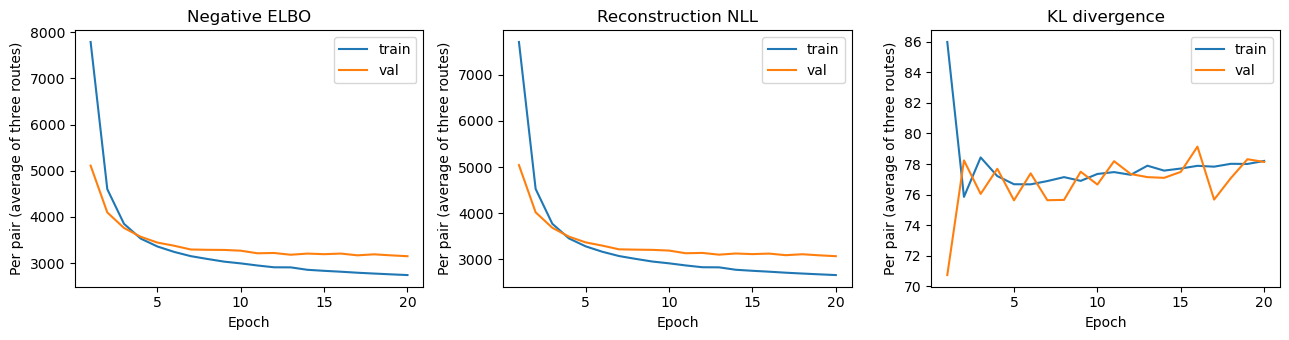

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for i, name in enumerate(["Negative ELBO", "Reconstruction NLL", "KL divergence"]):
    for split in ["train", "val"]:
        axes[i].plot(range(1, epochs + 1), np.array(history[split])[:, i], label=split)
    axes[i].set_title(name)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Per pair (average of three routes)")
    axes[i].legend()
fig.tight_layout()
fig.savefig(output_dir / "training_curves.png", dpi=150)
plt.show()


## 12. Evaluate on held-out pairs
We report the sampled training objective on held-out data and a simple pixel MSE for each route. MSE uses **posterior means** for stable reconstructions and is measured on [0, 1] pixels (divide [-1, 1] squared errors by four).

Cross-domain MSE compares against an arbitrary same-label partner. A correct digit with a different style can still have high error, so MSE is not a digit-recognition score. Use it with the visual examples, not as proof of semantic accuracy.


In [13]:
torch.manual_seed(SEED + 100)
test_metrics = run_epoch(my_vae, testloader)
print("Held-out negative ELBO / reconstruction NLL / KL:", test_metrics)

@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    totals = np.zeros((3, 2))
    count = 0
    for xm, xs, _ in loader:
        xm, xs = xm.to(device), xs.to(device)
        for route, (a, b) in enumerate([(xm, xs), (xm, None), (None, xs)]):
            rm, rs, _, _ = model(a, b, flag_sample=False)
            totals[route, 0] += ((rm - xm) ** 2).flatten(1).mean(1).sum().item() / 4
            totals[route, 1] += ((rs - xs) ** 2).flatten(1).mean(1).sum().item() / 4
        count += len(xm)
    return totals / count

mse = evaluate_mse(my_vae, testloader)
for name, values in zip(["Both inputs", "MNIST only", "SVHN only"], mse):
    print(f"{name:12s} | MNIST MSE {values[0]:.5f} | SVHN MSE {values[1]:.5f}")
run_info["test_negative_elbo_reconstruction_kl"] = test_metrics.tolist()
run_info["test_mse_rows_joint_mnist_svhn"] = mse.tolist()
(output_dir / "run_info.json").write_text(json.dumps(run_info, indent=2))


Held-out negative ELBO / reconstruction NLL / KL: [4249.85347383 4170.24004102   79.61343197]
Both inputs  | MNIST MSE 0.00450 | SVHN MSE 0.00871
MNIST only   | MNIST MSE 0.00430 | SVHN MSE 0.04983
SVHN only    | MNIST MSE 0.04786 | SVHN MSE 0.00528


4619

## 13. Joint reconstruction
Give the model both images, infer their shared latent mean, then decode it through both decoders. Using the mean removes sampling noise from this comparison. These are held-out examples, not training images.


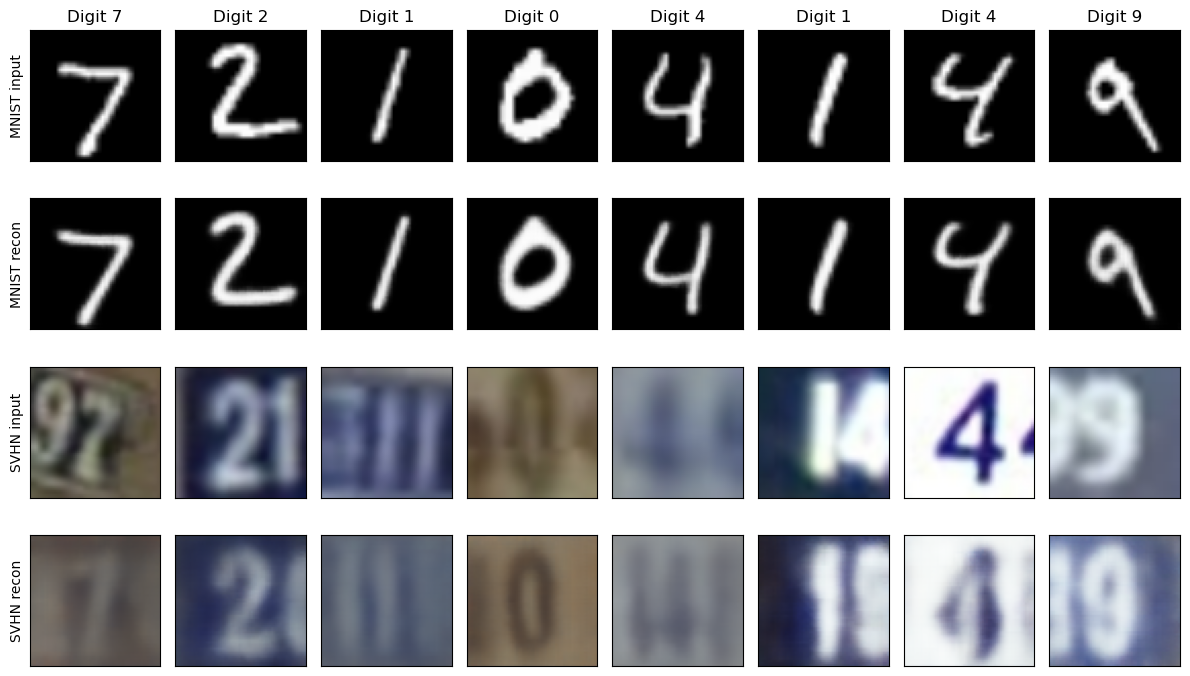

In [14]:
mnist_batch, svhn_batch, labels = next(iter(testloader))
x_mnist, x_svhn = mnist_batch.to(device), svhn_batch.to(device)
my_vae.eval()
with torch.no_grad():
    rec_mnist, rec_svhn, _, _ = my_vae(x_mnist, x_svhn, flag_sample=False)
show_rows([mnist_batch, rec_mnist, svhn_batch, rec_svhn],
          ["MNIST input", "MNIST recon", "SVHN input", "SVHN recon"],
          labels, "reconstructions.png")


## 14. Generation from the prior
Here there are **no input images**. Draw `z ~ N(0, I)` and decode each vector in both domains. Each column shares exactly the same `z`. Good joint generation would show consistent digit identities across rows; that is something to inspect, not assume.

We display decoder means, as in the CelebA lab. Sampling the fixed Gaussian observation noise would make noisier images and is not needed for this illustration.


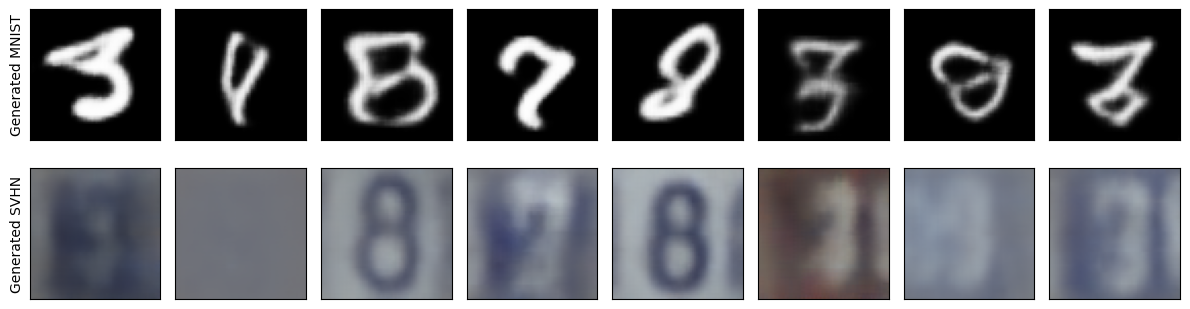

In [15]:
torch.manual_seed(SEED + 101)
with torch.no_grad():
    generated_mnist, generated_svhn = my_vae.sample(8)
show_rows([generated_mnist, generated_svhn], ["Generated MNIST", "Generated SVHN"],
          filename="prior_generation.png")


## 15. Cross-domain generation in both directions
For **MNIST → SVHN**, only the MNIST encoder is used; the inferred vector goes through the SVHN decoder. For **SVHN → MNIST**, reverse the roles. The target image is never passed to inference.

Posterior means give a stable comparison. We also sample several latent vectors for one MNIST input to inspect variation. Because the pairs share only a label, there is no uniquely correct target background or handwriting. A simple Gaussian decoder may average styles and produce blurry outputs.


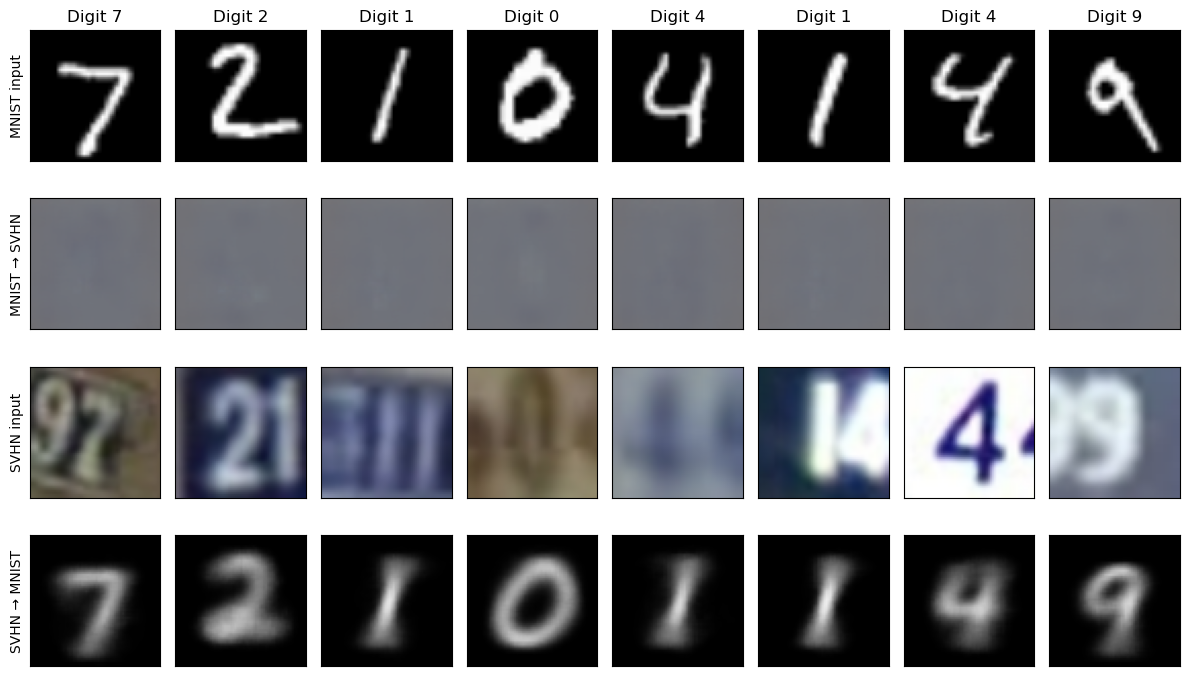

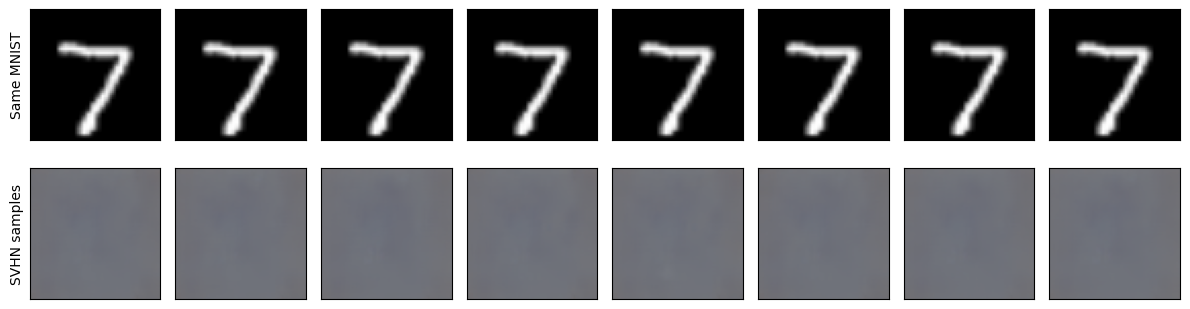

In [16]:
with torch.no_grad():
    _, mnist_to_svhn, _, _ = my_vae(x_mnist=x_mnist, flag_sample=False)
    svhn_to_mnist, _, _, _ = my_vae(x_svhn=x_svhn, flag_sample=False)
show_rows([mnist_batch, mnist_to_svhn, svhn_batch, svhn_to_mnist],
          ["MNIST input", "MNIST → SVHN", "SVHN input", "SVHN → MNIST"],
          labels, "cross_domain.png")

with torch.no_grad():
    mu, var = my_vae.infer(x_mnist=x_mnist[:1])
    z = mu + torch.randn(8, dimz, device=device) * torch.sqrt(var)
    variations = my_vae.decoder_svhn.decode(z)
show_rows([mnist_batch[:1].repeat(8, 1, 1, 1), variations],
          ["Same MNIST", "SVHN samples"], filename="cross_domain_variations.png")


## 16. Visualize the shared latent space with t-SNE
Collect posterior **means** from held-out images for all three inference routes. Fit **one t-SNE to the concatenation** so every route appears in the same 2D coordinate system. Separate fits would have unrelated axes.

Colors indicate true digit labels, which t-SNE does not use. Markers indicate which inputs were available. We use at most 500 pairs so the plot stays readable. `dimz=20` gives the model more capacity than a 2D latent space; t-SNE reduces it to two dimensions only for visualization.

Look for digit grouping and mixing between routes. t-SNE preserves some local neighborhoods, distorts global geometry, and depends on its seed/perplexity. A pretty cluster plot alone does not prove good generation.

We use seeded random initialization for t-SNE. The checks reject non-finite latent values or coordinates before plotting.


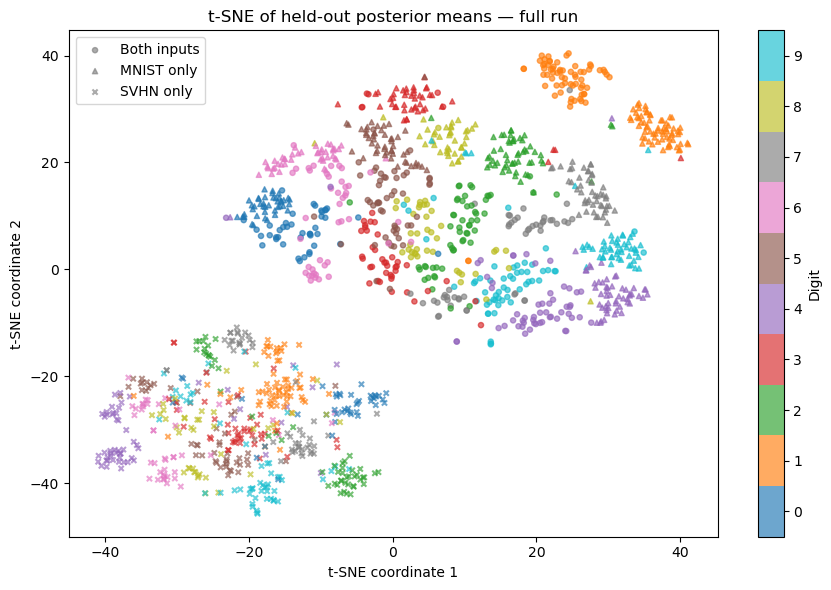

In [17]:
@torch.no_grad()
def collect_latents(model, loader, max_pairs=500):
    model.eval()
    joint, mnist_only, svhn_only, labels = [], [], [], []
    count = 0
    for xm, xs, y in loader:
        take = min(len(y), max_pairs - count)
        xm, xs = xm[:take].to(device), xs[:take].to(device)
        joint.append(model.infer(xm, xs)[0].cpu())
        mnist_only.append(model.infer(x_mnist=xm)[0].cpu())
        svhn_only.append(model.infer(x_svhn=xs)[0].cpu())
        labels.append(y[:take])
        count += take
        if count >= max_pairs:
            break
    return [torch.cat(values).numpy() for values in [joint, mnist_only, svhn_only, labels]]

z_joint, z_mnist, z_svhn, digit_labels = collect_latents(my_vae, testloader)
z_all = np.concatenate([z_joint, z_mnist, z_svhn])
assert np.isfinite(z_all).all()
embedding = TSNE(n_components=2, perplexity=30, init="random",
                 learning_rate="auto", random_state=SEED).fit_transform(z_all)
assert np.isfinite(embedding).all()
n = len(digit_labels)
fig, ax = plt.subplots(figsize=(9, 6))
for i, (name, marker) in enumerate([("Both inputs", "o"), ("MNIST only", "^"), ("SVHN only", "x")]):
    points = embedding[i*n:(i+1)*n]
    scatter = ax.scatter(points[:, 0], points[:, 1], c=digit_labels,
                         cmap="tab10", vmin=-0.5, vmax=9.5, marker=marker,
                         s=14, alpha=0.65, label=name)
fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
ax.legend()
ax.set_title("t-SNE of held-out posterior means — " + ("quick run" if QUICK_RUN else "full run"))
ax.set_xlabel("t-SNE coordinate 1")
ax.set_ylabel("t-SNE coordinate 2")
fig.tight_layout()
fig.savefig(output_dir / "latent_tsne.png", dpi=150)
plt.show()
np.savez(output_dir / "latent_tsne.npz", embedding=embedding, labels=digit_labels,
         z_joint=z_joint, z_mnist=z_mnist, z_svhn=z_svhn)


### Observations from the saved practice run
This saved execution used **2,048 training pairs, 256 validation pairs, three epochs, and 512 held-out test pairs on CPU**. The best validation checkpoint was epoch 3. Validation negative ELBO fell from approximately **16,798 to 12,898** per pair (averaged over the three routes).

The cross-domain panels still show mostly gray SVHN predictions and similar blurry MNIST predictions across different inputs. This run verifies that the implementation executes; it does **not** demonstrate successful digit translation. The latent visualization should be interpreted alongside those failures rather than used as proof of alignment.

Set `QUICK_RUN = False`, restart the kernel, and run all cells for the full experiment. Replace these observations with the evidence from that run before writing the report. Longer training may help, but does not guarantee success; assess the actual results.


## 17. Understand what you built
Before rewriting this in `main.ipynb`, try answering these questions:

1. Why would zipping two independently shuffled loaders produce incorrect pairs?
2. Why do we split the underlying SVHN images before making pairs?
3. What does `var_z` mean, and why does sampling use its square root?
4. Why does the product of experts weight a low-variance expert more strongly?
5. Why do the MNIST and SVHN decoders need separate parameters?
6. What would be missing if training used only the joint inference route?
7. How is prior generation different from reconstruction and cross-domain generation?
8. Why does a matching digit label not imply a matching image style?

**Useful experiments after the full baseline:** try a different latent dimension, inspect KL and reconstruction separately, or train without single-input routes and compare cross-domain results. Change one thing at a time. Use validation for decisions; reserve the test set for the final comparison.

**Common issues:** random-looking outputs before training are expected; blurry outputs after a tiny run are not evidence of success. Persistently identical generations may indicate insufficient learning or posterior collapse. Inspect curves and generated diversity before drawing conclusions. If training is slow on CPU, use a GPU environment or keep quick mode while learning the code. Full mode is still needed to judge the model fairly.


## 18. Preparing the two-page report
This notebook completes the implementation and produces the requested figures. The report should summarize **your actual run**, not claim success from having executable code.

**Page 1 — setup and method**
- Put all group members' names and a real, accessible code link at the beginning.
- Describe MNIST/SVHN, label-matched sampling with replacement, image transforms, and the disjoint training/validation/test construction. Give the actual pair counts.
- Explain the two encoders, shared latent vector, product-of-experts equation, two decoders, and three training routes.
- State latent dimension, fixed Gaussian observation variance, optimizer, learning rate, batch size, epochs, seed, and which checkpoint was selected. `run_info.json` records these.

**Page 2 — evidence and discussion**
- Include compact panels of reconstruction, prior generation, and both cross-domain directions, plus the t-SNE plot. Captions should identify the input/output rows.
- Give the held-out losses/MSE with units and the limitation of same-label partner MSE.
- Describe what you actually see: digit consistency, blur, diversity, failure cases, and latent grouping. Explain that same-label pairing does not align style.
- State whether results are from quick or full mode and acknowledge limitations. Do not claim convergence or high accuracy without evidence.

Upload the notebook to your own GitHub or Drive location, check the sharing permissions, and insert the real link. The course submission page may specify additional requirements; check it before submitting. This notebook does not publish files or submit coursework.

### References
- Provided course materials: `VAE-CelebA-example/Lab_VAEs.ipynb` and your `main.ipynb` (encoder, decoder, Gaussian likelihood and VAE loss conventions).
- Wu & Goodman, [Multimodal Generative Models for Scalable Weakly-Supervised Learning](https://arxiv.org/abs/1802.05335), 2018 (product-of-experts multimodal inference; our paired training objective is described above).
- [Torchvision MNIST](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html) and [SVHN](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.SVHN.html).
- [SVHN dataset](http://ufldl.stanford.edu/housenumbers/).
- [Scikit-learn t-SNE documentation](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).
